# 주문별 피킹 렉 · 레이아웃 위 점 표시

`layout_2026-09`(현재 A·B·C·D 레이아웃) 위에 **주문 1건의 피킹 렉을 점으로** 표시합니다.

- 기간: **2026-08-10 ~ 09-27** 출고 요청, `SHIPPED`, `pickingQuantity > 0`.
  데이터에서 옛 코드(X·I·W, C 도입 전 상온 A)가 사라진 뒤 구간입니다.
  6/1~8/9는 코드 체계가 바뀌는 중이라 현재 레이아웃에 찍지 않습니다(사용자 선택).
  코드 변경 시점은 출고 데이터에서 관측한 것이며 사용자 확인값이 아닙니다.
- 점 위치는 렉 칸의 중심(`cx`, `cy`)입니다. 작업자가 서는 통로 위치가 아닙니다.
  같은 렉의 다른 층·선반 피킹은 점 하나로 묶고 크기·숫자로 행 수를 표시합니다.
- **점은 할당된 로케이션**입니다. 실제 방문 위치·걸은 순서가 아니며 경로선은 그리지 않습니다.
- A·B·C_D는 서로 독립 좌표의 도면입니다. 공통 패킹 구역은 레이아웃에 좌표가 없어 표시하지 않습니다.
- 레이아웃에 없는 코드(M·S 등, 지도 미배치 렉, `~` 자리)는 주문별 **지도 미표시** 목록으로 따로 보여줍니다.

[레이아웃 설명](../docs/mfc_layout_array.md) · [운영 context](../docs/mfc_operating_context.md)

In [2]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

from hit_stocks_analysis import find_project_root
from hit_stocks_analysis.mfc_layout import load_layout

ROOT = find_project_root()
OUTPUT = ROOT / "reports/mfc_order_picks"
OUTPUT.mkdir(parents=True, exist_ok=True)
fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ("AppleGothic", "Malgun Gothic", "NanumGothic"):
    if font in fonts:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "#f8fafc"

layout = load_layout("2026-09")
ZONE_COLORS = {"A": "#3b82f6", "B": "#e11d48", "C": "#16a34a", "D": "#ca8a04"}
TITLES = {"A": "A · 냉동", "B": "B · 냉장", "C_D": "C·D · 상온"}
print(layout.version, {area: grid.shape for area, grid in layout.grids.items()})

2026-09 {'A': (32, 18), 'B': (26, 18), 'C_D': (27, 34)}


## 1. 피킹 행 불러오기와 렉 연결

`locationCode`에서 층·선반을 뺀 `A01-02` 형태의 렉 코드로 레이아웃 `racks`와 연결합니다.

In [3]:
SOURCE = ROOT / "outbound_2026-06-01_2026-09-27_2026-09-28_1152.csv"
START, END = "2026-08-10", "2026-09-28"  # END 미포함 · 자료는 9/27까지

picks = duckdb.sql(f"""
    select "orderId(주문번호)" as order_id, splitOrderId as split_order_id,
           cast(outboundRequestDateTime as timestamp) as requested_at,
           skuCode as sku_code, skuName as sku_name, locationCode as location_code,
           cast(pickingQuantity as integer) as picking_quantity,
           expirationDate as expiration_date
    from read_csv('{SOURCE}', all_varchar = true)
    where status = 'SHIPPED'
      and cast(outboundRequestDateTime as timestamp) >= '{START}'
      and cast(outboundRequestDateTime as timestamp) < '{END}'
      and cast(pickingQuantity as integer) > 0
""").df()
picks["rack_code"] = picks["location_code"].str.extract(r"^([ABCD]\d{2}-\d{2})-\d+$")[0]

placed = layout.racks.loc[layout.racks["observed"], ["area", "zone", "cx", "cy"]]
picks = picks.join(placed, on="rack_code")
picks["on_map"] = picks["cx"].notna()

orders = (picks.groupby("order_id")
          .agg(requested_at=("requested_at", "min"), lines=("sku_code", "size"),
               splits=("split_order_id", "nunique"), racks=("rack_code", "nunique"),
               off_map=("on_map", lambda s: int((~s).sum())))
          .sort_values("requested_at"))
print(f"기간 {picks['requested_at'].min()} ~ {picks['requested_at'].max()}")
print(f"주문 {len(orders):,}건 · 피킹 행 {len(picks):,}개 · "
      f"지도 표시 행 {picks['on_map'].mean():.1%}")
print("지도 미표시 행의 코드 앞 글자:",
      picks.loc[~picks["on_map"], "location_code"].str[0].value_counts().to_dict())

기간 2026-08-10 07:43:06 ~ 2026-09-27 23:59:41
주문 62,692건 · 피킹 행 451,594개 · 지도 표시 행 99.0%
지도 미표시 행의 코드 앞 글자: {'M': 2389, 'S': 936, 'D': 534, 'C': 462, 'B': 47, 'A': 3}


## 2. 주문 1건 그리기

- `show_order("주문번호")`: 지정한 주문을 그립니다.
- `nth_order(n)`: 요청 시각 순서로 n번째(0부터) 주문을 그립니다.
- `random_order(seed)`: 무작위로 한 건을 고릅니다. 같은 seed는 같은 주문입니다.
- `save=True`이면 `reports/mfc_order_picks/order_<주문번호>.png`로 저장합니다.

점 크기와 숫자는 해당 렉에서 피킹한 행 수입니다. 렉 칸은 연하게, 피킹한 렉은 존 색으로 칠합니다.

In [4]:
def draw_area(ax, area, order_picks):
    grid = layout.grids[area]
    background = np.full(grid.shape, 2)
    background[grid == "."] = 0
    background[grid == "#"] = 1
    ax.imshow(background, cmap=ListedColormap(["#ffffff", "#111827", "#e2e8f0"]),
              vmin=0, vmax=2, interpolation="nearest")
    for cell in layout.racks.loc[layout.racks["area"].eq(area)].itertuples():
        ax.add_patch(Rectangle((cell.x, cell.y), cell.width, cell.height,
                               facecolor="#f1f5f9" if cell.observed else "#fafafa",
                               edgecolor="#cbd5e1", linewidth=0.4))
    hits = (order_picks.loc[order_picks["area"].eq(area)]
            .groupby("rack_code").agg(zone=("zone", "first"), cx=("cx", "first"),
                                      cy=("cy", "first"), lines=("sku_code", "size")))
    for rack_code, hit in hits.iterrows():
        cell = layout.racks.loc[rack_code]
        ax.add_patch(Rectangle((cell.x, cell.y), cell.width, cell.height,
                               facecolor=ZONE_COLORS[hit.zone], alpha=0.25,
                               edgecolor=ZONE_COLORS[hit.zone], linewidth=1.2))
        ax.scatter(hit.cx, hit.cy, s=90 + 60 * (hit.lines - 1), color=ZONE_COLORS[hit.zone],
                   edgecolor="white", linewidth=1.2, zorder=3)
        label = rack_code if hit.lines == 1 else f"{rack_code} ×{hit.lines}"
        ax.annotate(label, (hit.cx, hit.cy), xytext=(6, 6), textcoords="offset points",
                    fontsize=8, fontweight="bold", zorder=4,
                    bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 1})
    ax.set(xlim=(-0.5, grid.shape[1] - 0.5), ylim=(grid.shape[0] - 0.5, -0.5))
    ax.set_xticks([])
    ax.set_yticks([])
    status = f"피킹 렉 {len(hits)}개" if len(hits) else "피킹 없음"
    ax.set_title(f"{TITLES[area]} · {status}", fontsize=13)


def show_order(order_id, save=False):
    order_id = str(order_id)
    order_picks = picks.loc[picks["order_id"].eq(order_id)]
    if order_picks.empty:
        raise KeyError(f"{order_id}: 기간 내 SHIPPED 피킹 행이 없는 주문번호입니다.")
    info = orders.loc[order_id]
    fig, axes = plt.subplots(1, 3, figsize=(24, 10), layout="constrained",
                             width_ratios=[g.shape[1] for g in layout.grids.values()])
    for ax, area in zip(axes, layout.grids):
        draw_area(ax, area, order_picks)
    split_note = f" · 분할 출고 {info.splits}건" if info.splits > 1 else ""
    fig.suptitle(f"주문 {order_id} · 요청 {info.requested_at:%Y-%m-%d %H:%M}\n"
                 f"피킹 {info.lines}행 · 렉 {info.racks}개 · 지도 미표시 {info.off_map}행"
                 f"{split_note}\n점 = 할당 로케이션의 렉 칸 중심 · 실제 이동 순서·경로 아님",
                 fontsize=15)
    if save:
        fig.savefig(OUTPUT / f"order_{order_id}.png", dpi=150, bbox_inches="tight")
    plt.show()
    columns = ["split_order_id", "rack_code", "location_code", "sku_code", "sku_name",
               "picking_quantity", "expiration_date", "on_map"]
    display(order_picks[columns].sort_values(["on_map", "location_code"],
                                             ascending=[False, True]).reset_index(drop=True))


def nth_order(n, save=False):
    show_order(orders.index[n], save=save)


def random_order(seed=None, save=False):
    show_order(orders.sample(1, random_state=seed).index[0], save=save)

## 3. 예시

주문번호를 바꿔 실행하세요. 아래는 재현 가능한 무작위 예시입니다.

findfont: Failed to find font weight bold for AppleGothic, now using 400.


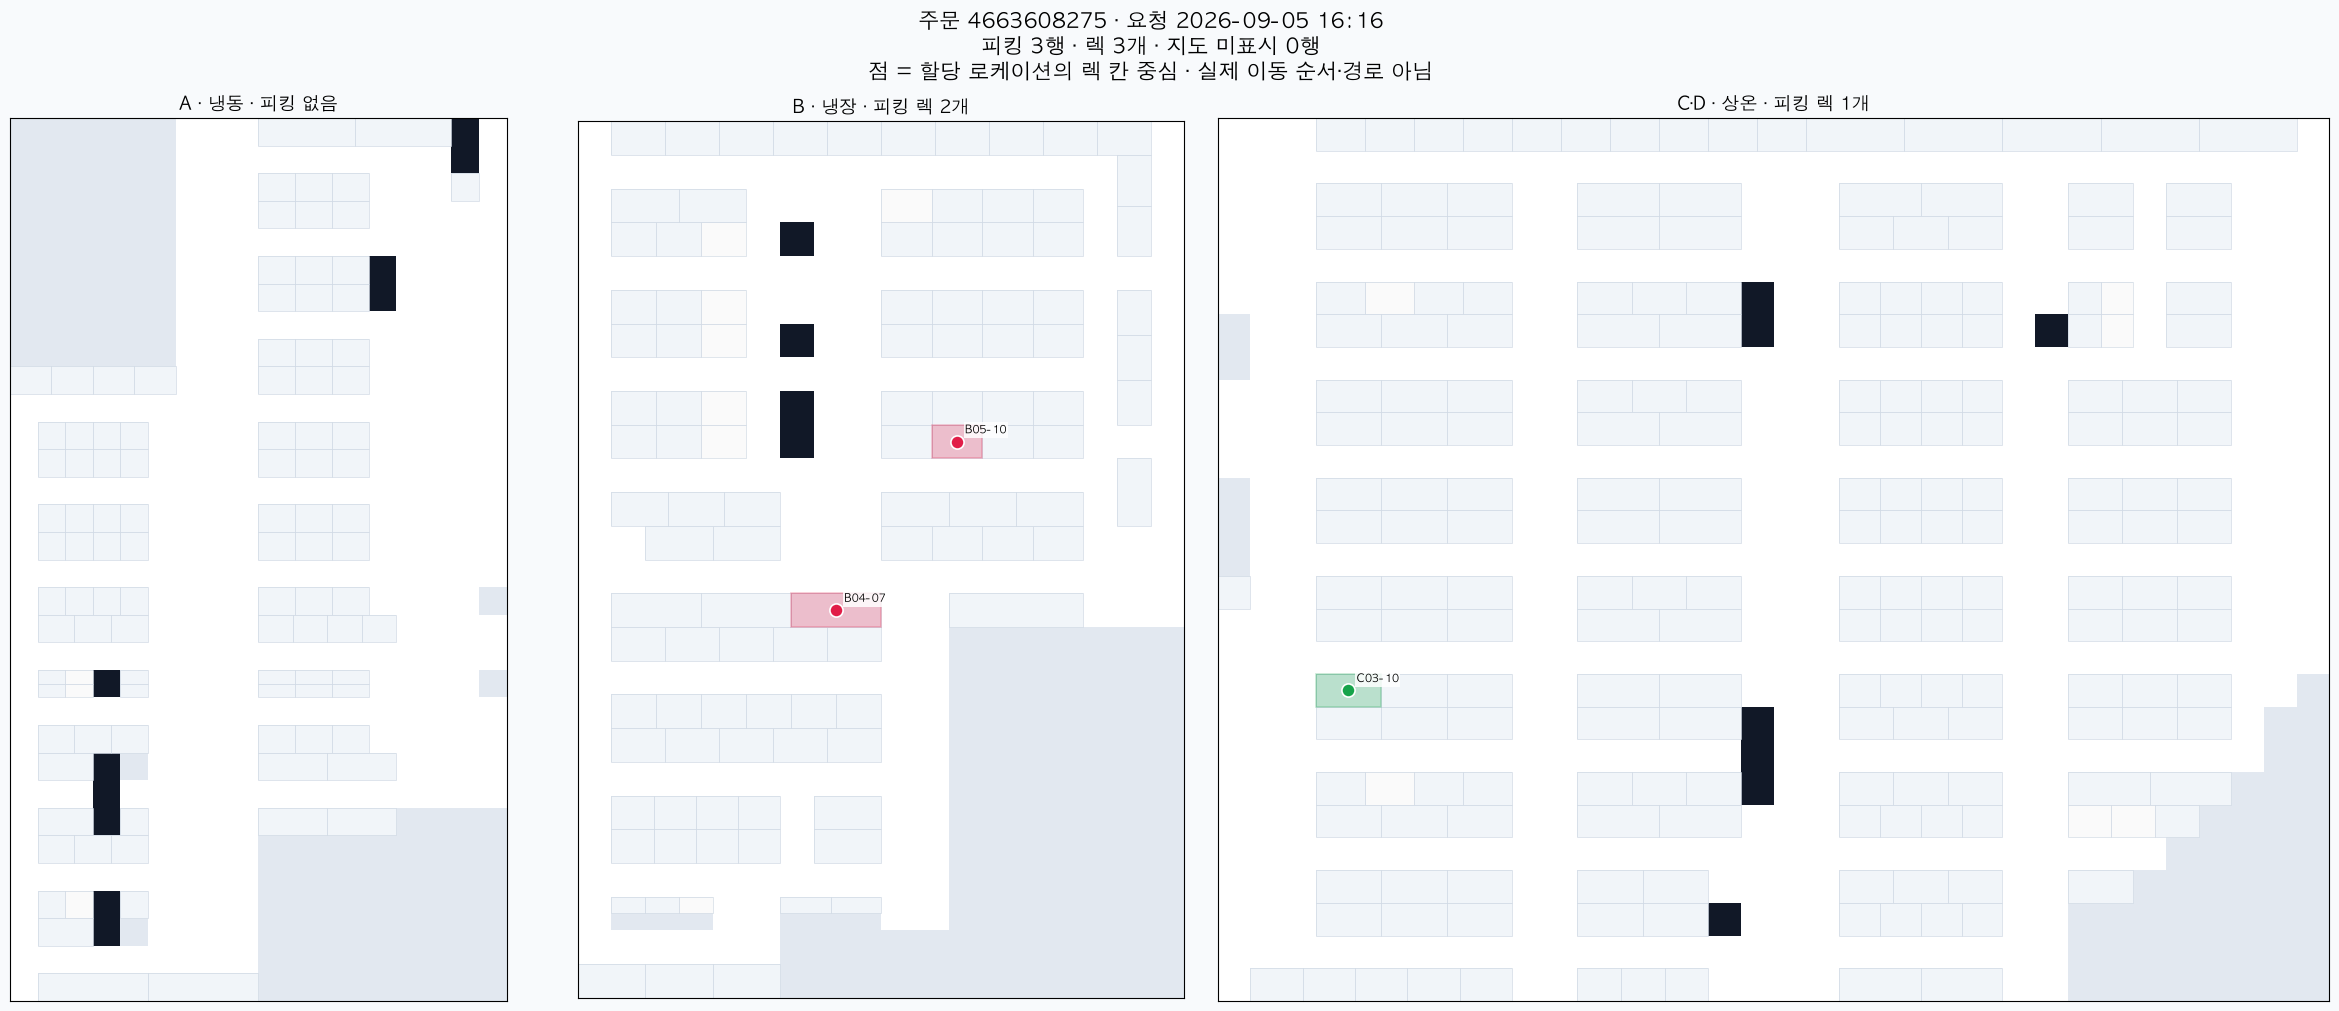

,split_order_id,rack_code,location_code,sku_code,sku_name,picking_quantity,expiration_date,on_map
0,304052100,B04-07,B04-07-302,A20001501,양지뜨레 동물복지 유정란 대란 15구,1,2026-10-01,True
1,304052100,B05-10,B05-10-306,S0013233,알라 고다 슬라이스 치즈 150g,1,2027-01-31,True
2,304052100,C03-10,C03-10-401,A21006866,햇반 작은공기 130g 3입,1,2027-05-05,True


In [5]:
random_order(seed=0, save=True)

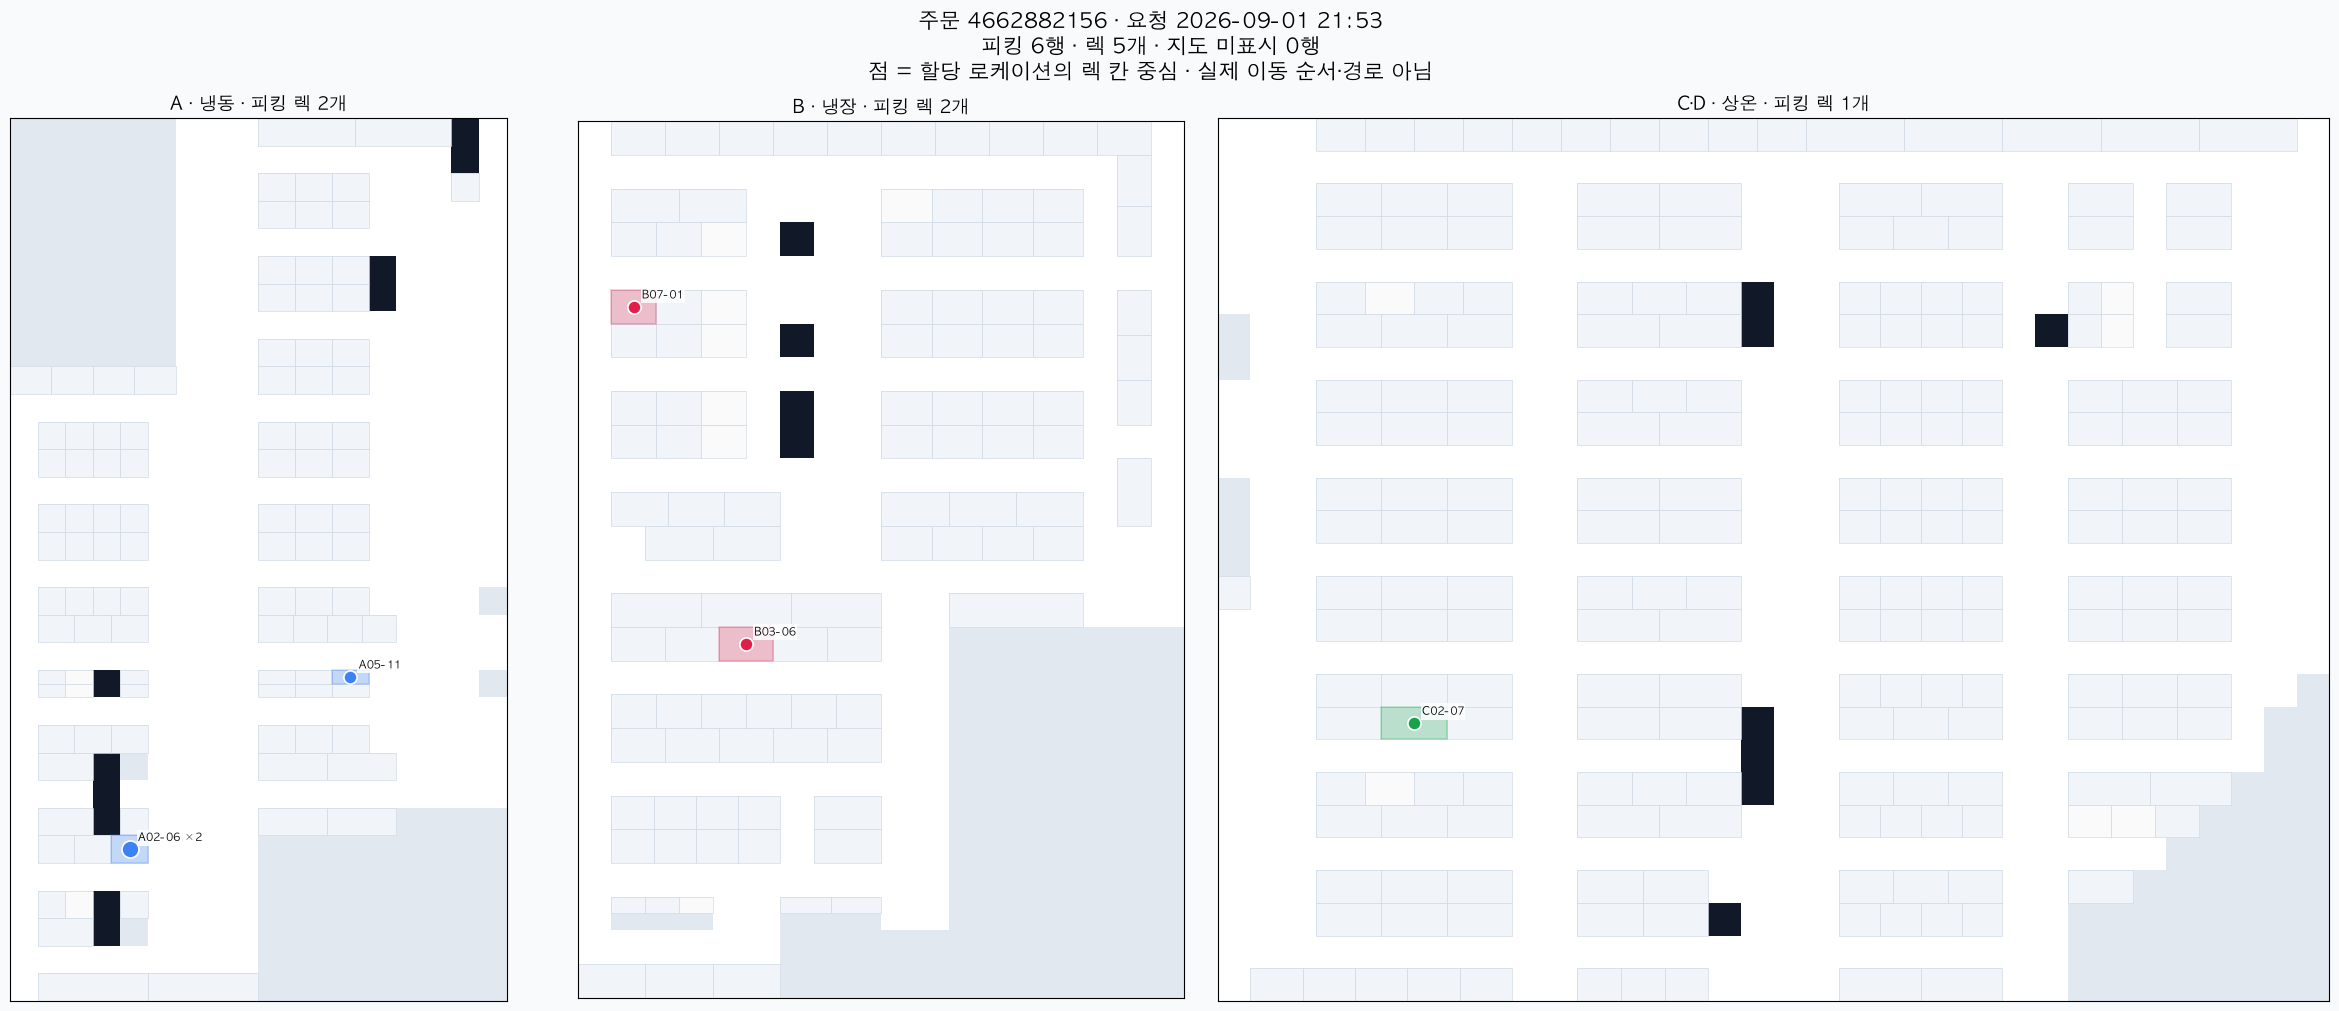

,split_order_id,rack_code,location_code,sku_code,sku_name,picking_quantity,expiration_date,on_map
0,303731547,A02-06,A02-06-101,S0003844,집밥에 소곱창 180g (참소스 20g 포함),1,2027-08-18,True
1,303731547,A02-06,A02-06-204,S0003786,집밥에 소막창 200g (참소스 20g 포함),1,2027-08-04,True
2,303731547,A05-11,A05-11-208,S0003646,[배민이지] 매콤한 국내산 직화 무뼈닭발 300g,1,2027-08-05,True
3,303731547,B03-06,B03-06-106,S0001978,장충동왕족발 쫄깃한편육 215g (냉장),1,2026-09-27,True
4,303731547,B07-01,B07-01-705,S0003392,[배민이지] 속이 꽉 차고 찰진 통순대 400g,1,2026-09-21,True
5,303731547,C02-07,C02-07-301,A21002033,오리온 초코칩 쿠키 104g,1,2027-08-06,True


In [9]:
# 여러 존을 오가는 주문 예시: 렉이 5개 이상인 주문 중 하나
many_racks = orders.index[orders["racks"].ge(5)]
show_order(many_racks[len(many_racks) // 2], save=True)